# 06 · BV vs THINGS vs a comparison dataset

**What it does.** The analogue of manuscript notebooks 02 and 03, on the categories the comparison dataset covers, for
both category sets (hyponym and exclusive) and both models.
1. **Category-wise cosine** between matched category vectors for each dataset pair.
2. **RDM comparison:** cosine-distance RDMs; upper-triangle Spearman / Pearson per pair; one-sided **label-shuffle
   permutation** p (5,000, as notebook 03); **category bootstrap** 95% CI (2,000, pairs of the same original
   category dropped); bootstrap CI of ρ(BV, dataset) − ρ(BV, THINGS).
3. **CLIP vs DINOv3** RDM agreement within each dataset.
4. **Figures:** RDMs in CDI-domain blocks, alphabetical (manuscript convention) and clustered within domain on BV or
   on the comparison dataset.

The environment variables `BV_RDM_BASELINE_N_PERM` / `BV_RDM_N_BOOT` shrink resampling for quick runs.
**Outputs:** `outputs/bv_<dataset>/results/` and `figures/`.

In [1]:
# Standard setup shared by every notebook (each notebook is self-contained).
import json
import os
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage, optimal_leaf_ordering
from scipy.spatial.distance import pdist, squareform
from scipy.stats import false_discovery_control, pearsonr, rankdata, spearmanr, wilcoxon
from IPython.display import Image, Markdown, display

plt.rcParams["font.family"] = ["DejaVu Sans", "sans-serif"]
pd.set_option("display.max_colwidth", 120)


def show_images(paths, width=950):
    """Display saved figures (the files this notebook writes)."""
    for p in map(Path, paths):
        if p.exists():
            display(Markdown(f"`{p.relative_to(ROOT)}`")); display(Image(filename=str(p), width=width))
        else:
            display(Markdown(f"*Missing figure:* `{p}`"))

In [2]:
# Paths. Run this notebook from analysis/comparison-datasets/notebooks/ (Jupyter's default working directory).
ROOT = Path.cwd().resolve().parent                     # analysis/comparison-datasets
assert (ROOT / "notebooks").is_dir(), "open this notebook from analysis/comparison-datasets/notebooks/"
REPO = ROOT.parents[1]
DATA_DIR = REPO / "data"
MANUSCRIPT_DIR = REPO / "analysis" / "manuscript-2026"
VEDB_DIR = REPO / "analysis" / "vedb-1612"
VOCAB_DIR = DATA_DIR / "vocabulary_lists"
VALID129_TXT = VOCAB_DIR / "included_categories_valid129.txt"

# Inputs written by other pipelines (read only).
EXEMPLAR_EMBED_ROOT = Path(os.environ.get("BV_EXEMPLAR_EMBED_ROOT",
                                          str(MANUSCRIPT_DIR / "exemplar_set_embeddings"))).expanduser()
BV_THINGS_VALID129 = EXEMPLAR_EMBED_ROOT / "valid129"       # manuscript Stage 0: BV + THINGS tables
VEDB_VALID129 = VEDB_DIR / "exemplar_set_embeddings" / "valid129"   # vedb-1612 Stage 0 (files use the "bv_" prefix)

# External data on ccn2.
IMAGENET_DIR = Path("/data2/j7yang/imagenet-1k/extracted")
IMAGENET_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/imagenet_1k/outputs/image_embeddings")
LVIS_ROOT = Path("/data2/j7yang/lvis")
LVIS_CROP_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/lvis/outputs/crop_embeddings")

# Outputs of this folder.
OUT = ROOT / "outputs"
MAPPING_OUT = OUT / "mapping"
MONTAGE_OUT = OUT / "montages"
EXEMPLAR_SETS = OUT / "exemplar_sets"
MODELS = ("clip", "dinov3")

## Parameters

In [3]:
DATASET = "lvis"
assert DATASET in ('imagenet', 'lvis'), "DATASET must be one of ('imagenet', 'lvis')"

## Configuration and loading

In [4]:
def load_cdi_semantic_map() -> dict[str, str]:
    """``uni_lemma`` → CDI semantic domain from ``data/cdi_words.csv``.

    Frequency tables under ``data/long_tailed_dist_prop_included_categories_*.csv``
    are not a semantic source: the unfiltered valid129 file currently copies
    valid85 labels and marks the extra 44 categories as ``other``.
    """
    import pandas as pd

    path = DATA_DIR / "cdi_words.csv"
    df = pd.read_csv(path, usecols=["uni_lemma", "category"])
    df["uni_lemma"] = df["uni_lemma"].astype(str).str.strip().str.lower()
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return (
        df.drop_duplicates(subset=["uni_lemma"], keep="first")
        .set_index("uni_lemma")["category"]
        .to_dict()
    )


CMP_LABELS = {"imagenet": "ImageNet", "lvis": "LVIS"}
CMP = CATEGORY_SETS = DATASETS = LABEL = PAIRS = PAIR_COLOR = None


def configure(dataset: str) -> None:
    """Point the module at one comparison dataset (imagenet | lvis)."""
    global CMP, CATEGORY_SETS, DATASETS, LABEL, PAIRS, PAIR_COLOR, OUT_ROOT, RESULTS_DIR, FIGURES_DIR
    CMP = dataset
    # Category sets written by comparison_exemplar_set_zscore_embeddings.py: <dataset>_{hyponym,exclusive}<n>
    sets = []
    for variant in ("hyponym", "exclusive"):
        found = sorted(p.name for p in EXEMPLAR_SETS.glob(f"{dataset}_{variant}[0-9]*") if p.is_dir())
        if len(found) != 1:  # a stale folder from an older mapping would otherwise be picked silently
            raise SystemExit(f"expected one {dataset}_{variant}<n> folder in {EXEMPLAR_SETS}, found {found}")
        sets.append(found[0])
    CATEGORY_SETS = tuple(sets)
    DATASETS = ("bv", "things", dataset)
    LABEL = {"bv": "BV", "things": "THINGS", dataset: CMP_LABELS[dataset]}
    PAIRS = (("bv", dataset), ("bv", "things"), ("things", dataset))
    PAIR_COLOR = {  # categorical slots 1-3 of the dataviz reference palette, fixed per pair
        ("bv", dataset): "#2a78d6",
        ("bv", "things"): "#eb6834",
        ("things", dataset): "#1baf7a",
    }
    OUT_ROOT = OUT / f"bv_{dataset}"
    RESULTS_DIR = OUT_ROOT / "results"
    FIGURES_DIR = OUT_ROOT / "figures"


def load_table(ds: str, model: str, set_name: str) -> tuple[list[str], np.ndarray]:
    df = pd.read_csv(EXEMPLAR_SETS / set_name / f"{ds}_{model}_exemplar_avg_zscore_within_{set_name}.csv")
    return df["category"].tolist(), df.filter(like="dim_").to_numpy(dtype=np.float64)

## Statistics and ordering

In [5]:
CDI_SEMANTIC_COLORS = {  # same as notebook 03
    "animals": "#4DB8A8", "body_parts": "#E87A5F", "clothing": "#9B7EC8",
    "food_drink": "#E8A54C", "furniture_rooms": "#6BAB7A", "household": "#D97B9E",
    "outside": "#5B9BD5", "toys": "#B07CC8", "vehicles": "#6BA3D5", "other": "#8B9A9E",
}
CDI_SEMANTIC_ORDER = ["animals", "body_parts", "clothing", "food_drink", "furniture_rooms",
                      "household", "outside", "toys", "vehicles", "other"]
N_PERM = int(os.environ.get("BV_RDM_BASELINE_N_PERM", "5000"))
N_BOOT = int(os.environ.get("BV_RDM_N_BOOT", "2000"))
SEED = int(os.environ.get("BV_RDM_BASELINE_SEED", "2026"))


def semantic_order(cats: list[str], sem: dict[str, str], ref_rdm: np.ndarray | None = None
                   ) -> tuple[np.ndarray, list[str]]:
    """Indices ordering categories by CDI domain (fixed order). Within a domain:
    alphabetical (as in notebook 03) if ref_rdm is None, else average-linkage
    hierarchical clustering on ref_rdm's within-domain block with optimal leaf ordering."""
    labels = [sem.get(c, "other") if sem.get(c, "other") in CDI_SEMANTIC_ORDER else "other" for c in cats]
    order: list[int] = []
    for dom in CDI_SEMANTIC_ORDER:
        idx = sorted((i for i in range(len(cats)) if labels[i] == dom), key=lambda i: cats[i])
        if ref_rdm is not None and len(idx) > 2:
            sub = ref_rdm[np.ix_(idx, idx)]
            Z = optimal_leaf_ordering(linkage(squareform(sub, checks=False), method="average"),
                                      squareform(sub, checks=False))
            idx = [idx[k] for k in leaves_list(Z)]
        order.extend(idx)
    return np.array(order), [labels[i] for i in order]


def upper(rdm: np.ndarray) -> np.ndarray:
    return rdm[np.triu_indices_from(rdm, k=1)]


def perm_p_spearman(rdm_a: np.ndarray, rdm_b: np.ndarray, observed: float, rng) -> tuple[float, float]:
    """One-sided p for Spearman(rdm_a, rdm_b) under shuffling rdm_b's category labels."""
    n = rdm_a.shape[0]
    iu = np.triu_indices(n, k=1)
    ra = rankdata(rdm_a[iu])
    ra = (ra - ra.mean()) / ra.std()
    null = np.empty(N_PERM)
    for k in range(N_PERM):
        p = rng.permutation(n)
        rb = rankdata(rdm_b[np.ix_(p, p)][iu])
        null[k] = np.mean(ra * (rb - rb.mean()) / rb.std())
    return float((np.sum(null >= observed) + 1) / (N_PERM + 1)), float(null.mean())


def bootstrap_spearman(rdms: dict, rng) -> dict:
    """Category bootstrap: resample categories, drop pairs of the same original category."""
    n = next(iter(rdms.values())).shape[0]
    iu = np.triu_indices(n, k=1)
    out = {pair: np.empty(N_BOOT) for pair in PAIRS}
    for k in range(N_BOOT):
        idx = rng.integers(0, n, n)
        keep = idx[iu[0]] != idx[iu[1]]
        vecs = {ds: rdms[ds][np.ix_(idx, idx)][iu][keep] for ds in DATASETS}
        for a, b in PAIRS:
            out[(a, b)][k] = spearmanr(vecs[a], vecs[b])[0]
    return out

## Figures

In [6]:
def plot_rdms(set_name, model, cats, rdms, order, sem_labels, rho, order_name):
    """Three RDM panels in one shared order; BV panel carries category names colored by domain."""
    n = len(cats)
    fig, axes = plt.subplots(1, 3, figsize=(17, 6.2), constrained_layout=True)
    bounds = [i for i in range(1, n) if sem_labels[i] != sem_labels[i - 1]]
    starts, ends = [0] + bounds, bounds + [n]
    for ax, ds in zip(axes, DATASETS):
        im = ax.imshow(rdms[ds][np.ix_(order, order)], cmap="viridis", vmin=0, vmax=2)
        for b in bounds:
            ax.axhline(b - 0.5, color="white", lw=0.8)
            ax.axvline(b - 0.5, color="white", lw=0.8)
        title = LABEL[ds]
        if ds != "bv":
            title += f"   (ρ with BV = {rho[('bv', ds)]:.2f})"
        ax.set_title(title, fontsize=11)
        ax.set_yticks([])
        # domain names under each panel, centered on their block
        ax.set_xticks([(s_ + e_ - 1) / 2 for s_, e_ in zip(starts, ends)])
        ax.set_xticklabels([sem_labels[s_].replace("_", " ") for s_ in starts], rotation=45, ha="right", fontsize=7.5)
        ax.tick_params(axis="x", length=0)
        for tick, s_ in zip(ax.get_xticklabels(), starts):
            tick.set_color(CDI_SEMANTIC_COLORS.get(sem_labels[s_], CDI_SEMANTIC_COLORS["other"]))
    axes[0].set_yticks(np.arange(n))
    axes[0].set_yticklabels([cats[i] for i in order], fontsize=4.6)
    axes[0].tick_params(axis="y", length=0, pad=1)
    for tick, lab in zip(axes[0].get_yticklabels(), sem_labels):
        tick.set_color(CDI_SEMANTIC_COLORS.get(lab, CDI_SEMANTIC_COLORS["other"]))
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="cosine distance")
    how = "alphabetical" if order_name == "alpha" else f"clustered on {LABEL[order_name.split('_')[1]]} RDM"
    fig.suptitle(f"{model.upper()} category RDMs, CDI domains, {how} within domain ({set_name}, n={n})", fontsize=12)
    suffix = "" if order_name == "alpha" else f"_{order_name}"
    stem = FIGURES_DIR / f"rdms_bv_things_{CMP}_{model}_{set_name}{suffix}"
    fig.savefig(stem.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)


def plot_summary(rdm_df: pd.DataFrame):
    fig, axes = plt.subplots(1, len(CATEGORY_SETS), figsize=(11, 4), sharey=True, constrained_layout=True)
    w = 0.26
    for ax, set_name in zip(axes, CATEGORY_SETS):
        d = rdm_df[rdm_df["category_set"] == set_name]
        for j, (a, b) in enumerate(PAIRS):
            dd = d[(d["dataset_a"] == a) & (d["dataset_b"] == b)].set_index("model").loc[list(MODELS)]
            x = np.arange(len(MODELS)) + (j - 1) * w
            ax.bar(x, dd["spearman_r"], width=w - 0.03, color=PAIR_COLOR[(a, b)],
                   label=f"{LABEL[a]}–{LABEL[b]}")
            ax.errorbar(x, dd["spearman_r"],
                        yerr=[dd["spearman_r"] - dd["boot_ci_lo"], dd["boot_ci_hi"] - dd["spearman_r"]],
                        fmt="none", ecolor="#52514e", elinewidth=1, capsize=2)
        ax.set_xticks(np.arange(len(MODELS)))
        ax.set_xticklabels([m.upper() for m in MODELS])
        ax.set_title(f"{set_name} (n={int(d['n_categories'].iloc[0])})", fontsize=11)
        ax.axhline(0, color="#52514e", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e6e5e0", lw=0.6)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("RDM Spearman ρ (95% category-bootstrap CI)")
    axes[-1].legend(frameon=False, loc="upper right", fontsize=9)
    stem = FIGURES_DIR / f"rdm_spearman_summary_bv_things_{CMP}"
    fig.savefig(stem.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)

## The analysis

In [7]:
def bv_vs_comparison(dataset: str):
    """BV vs THINGS vs one comparison dataset ('imagenet' | 'lvis'): write results and figures; return the tables."""
    configure(dataset)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    sem = load_cdi_semantic_map()
    rng = np.random.default_rng(SEED)

    rdm_rows, cos_rows, anchor_rows, lines = [], [], [], []
    for set_name in CATEGORY_SETS:
        rdm_by_model = {}
        for model in MODELS:
            emb = {}
            for ds in DATASETS:
                cats_ds, emb[ds] = load_table(ds, model, set_name)
                if ds == "bv":
                    cats = cats_ds
                assert cats_ds == cats, f"category mismatch {ds} {model} {set_name}"
            n = len(cats)

            # 1. category-wise cosine (02 analogue)
            for i, c in enumerate(cats):
                row = {"category_set": set_name, "model": model, "category": c, "cdi_semantic": sem.get(c, "other")}
                for a, b in PAIRS:
                    va, vb = emb[a][i], emb[b][i]
                    row[f"cos_{a}_{b}"] = float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb)))
                cos_rows.append(row)

            # 2. RDM comparison (03 analogue)
            rdms = {ds: squareform(pdist(emb[ds], metric="cosine")) for ds in DATASETS}
            rdm_by_model[model] = rdms
            boot = bootstrap_spearman(rdms, rng)
            rho = {}
            for a, b in PAIRS:
                va, vb = upper(rdms[a]), upper(rdms[b])
                sr = spearmanr(va, vb)[0]
                rho[(a, b)] = sr
                p_perm, null_mean = perm_p_spearman(rdms[a], rdms[b], sr, rng)
                lo, hi = np.percentile(boot[(a, b)], [2.5, 97.5])
                rdm_rows.append({
                    "category_set": set_name, "model": model, "dataset_a": a, "dataset_b": b,
                    "n_categories": n, "n_pairs": len(va),
                    "pearson_r": pearsonr(va, vb)[0], "spearman_r": sr,
                    "perm_p_spearman": p_perm, "perm_null_mean_spearman": null_mean,
                    "boot_ci_lo": lo, "boot_ci_hi": hi,
                })
            diff = boot[("bv", CMP)] - boot[("bv", "things")]
            dlo, dhi = np.percentile(diff, [2.5, 97.5])
            rdm_rows.append({
                "category_set": set_name, "model": model, "dataset_a": f"bv-{CMP}", "dataset_b": "minus bv-things",
                "n_categories": n, "spearman_r": rho[("bv", CMP)] - rho[("bv", "things")],
                "boot_ci_lo": dlo, "boot_ci_hi": dhi,
                "perm_p_spearman": np.nan,
            })

            # Alphabetical within domain (notebook 03 convention), then within-domain
            # clustering using BV or the comparison dataset as the reference order (same order on all panels).
            for order_name, ref in (("alpha", None), ("clustered_bv", "bv"), (f"clustered_{CMP}", CMP)):
                order, sem_labels = semantic_order(cats, sem, None if ref is None else rdms[ref])
                plot_rdms(set_name, model, cats, rdms, order, sem_labels, rho, order_name)

        # 3. CLIP vs DINOv3 within each dataset
        for ds in DATASETS:
            anchor_rows.append({
                "category_set": set_name, "dataset": ds,
                "spearman_clip_vs_dinov3": spearmanr(upper(rdm_by_model["clip"][ds]),
                                                     upper(rdm_by_model["dinov3"][ds]))[0],
            })

    rdm_df = pd.DataFrame(rdm_rows)
    cos_df = pd.DataFrame(cos_rows)
    anchor_df = pd.DataFrame(anchor_rows)
    rdm_df.to_csv(RESULTS_DIR / f"rdm_comparison_bv_things_{CMP}.csv", index=False)
    cos_df.to_csv(RESULTS_DIR / f"category_wise_cosine_bv_things_{CMP}.csv", index=False)
    anchor_df.to_csv(RESULTS_DIR / "clip_vs_dinov3_rdm_anchor_by_dataset.csv", index=False)
    plot_summary(rdm_df[rdm_df["dataset_a"].isin(DATASETS)])

    # text summary
    lines.append(f"BV vs {LABEL[CMP]} vs THINGS (n_perm={N_PERM}, n_boot={N_BOOT}, seed={SEED})\n")
    for set_name in CATEGORY_SETS:
        lines.append(f"== {set_name}")
        for model in MODELS:
            d = rdm_df[(rdm_df["category_set"] == set_name) & (rdm_df["model"] == model)]
            lines.append(f"  {model}: n_categories={int(d['n_categories'].iloc[0])}")
            for _, r in d.iterrows():
                p = "" if pd.isna(r["perm_p_spearman"]) else f", perm p={r['perm_p_spearman']:.4f}"
                lines.append(f"    RDM {r['dataset_a']} vs {r['dataset_b']}: Spearman={r['spearman_r']:.3f} "
                             f"[{r['boot_ci_lo']:.3f}, {r['boot_ci_hi']:.3f}]{p}")
            c = cos_df[(cos_df["category_set"] == set_name) & (cos_df["model"] == model)]
            w = wilcoxon(c[f"cos_bv_{CMP}"], c["cos_bv_things"])
            lab = LABEL[CMP]
            lines.append(f"    category cosine mean: BV-{lab}={c[f'cos_bv_{CMP}'].mean():.3f}, "
                         f"BV-THINGS={c['cos_bv_things'].mean():.3f}, THINGS-{lab}={c[f'cos_things_{CMP}'].mean():.3f}"
                         f"  (Wilcoxon BV-{lab} vs BV-THINGS p={w.pvalue:.3g})")
        a = anchor_df[anchor_df["category_set"] == set_name]
        lines.append("  CLIP vs DINOv3 RDM Spearman: " + ", ".join(
            f"{LABEL[r.dataset]}={r.spearman_clip_vs_dinov3:.3f}" for r in a.itertuples()))
        lines.append("")
    text = "\n".join(lines)
    (RESULTS_DIR / f"summary_bv_things_{CMP}.txt").write_text(text)
    print(text)

    return {"rdm": rdm_df, "cosine": cos_df, "clip_vs_dinov3": anchor_df, "summary": text}

## Run (~1–2 min)

In [8]:
res = bv_vs_comparison(DATASET)

BV vs LVIS vs THINGS (n_perm=5000, n_boot=2000, seed=2026)

== lvis_hyponym105
  clip: n_categories=105
    RDM bv vs lvis: Spearman=0.492 [0.404, 0.582], perm p=0.0002
    RDM bv vs things: Spearman=0.596 [0.533, 0.661], perm p=0.0002
    RDM things vs lvis: Spearman=0.410 [0.339, 0.490], perm p=0.0002
    RDM bv-lvis vs minus bv-things: Spearman=-0.104 [-0.191, -0.022]
    category cosine mean: BV-LVIS=0.616, BV-THINGS=0.611, THINGS-LVIS=0.490  (Wilcoxon BV-LVIS vs BV-THINGS p=0.128)
  dinov3: n_categories=105
    RDM bv vs lvis: Spearman=0.527 [0.454, 0.599], perm p=0.0002
    RDM bv vs things: Spearman=0.409 [0.352, 0.461], perm p=0.0002
    RDM things vs lvis: Spearman=0.347 [0.289, 0.402], perm p=0.0002
    RDM bv-lvis vs minus bv-things: Spearman=0.118 [0.045, 0.197]
    category cosine mean: BV-LVIS=0.621, BV-THINGS=0.480, THINGS-LVIS=0.464  (Wilcoxon BV-LVIS vs BV-THINGS p=2.7e-10)
  CLIP vs DINOv3 RDM Spearman: BV=0.889, THINGS=0.511, LVIS=0.870

== lvis_exclusive104
  clip: 

## RDM correlations

In [9]:
res["rdm"].round(3)

,category_set,model,dataset_a,dataset_b,n_categories,n_pairs,pearson_r,spearman_r,perm_p_spearman,perm_null_mean_spearman,boot_ci_lo,boot_ci_hi
0,lvis_hyponym105,clip,bv,lvis,105,5460.0,0.539,0.492,0.0,-0.0,0.404,0.582
1,lvis_hyponym105,clip,bv,things,105,5460.0,0.698,0.596,0.0,0.0,0.533,0.661
2,lvis_hyponym105,clip,things,lvis,105,5460.0,0.477,0.410,0.0,-0.0,0.339,0.490
3,lvis_hyponym105,clip,bv-lvis,minus bv-things,105,NaN,NaN,-0.104,NaN,NaN,-0.191,-0.022
4,lvis_hyponym105,dinov3,bv,lvis,105,5460.0,0.608,0.527,0.0,-0.0,0.454,0.599
5,lvis_hyponym105,dinov3,bv,things,105,5460.0,0.547,0.409,0.0,-0.0,0.352,0.461
6,lvis_hyponym105,dinov3,things,lvis,105,5460.0,0.491,0.347,0.0,0.0,0.289,0.402
7,lvis_hyponym105,dinov3,bv-lvis,minus bv-things,105,NaN,NaN,0.118,NaN,NaN,0.045,0.197
8,lvis_exclusive104,clip,bv,lvis,104,5356.0,0.531,0.486,0.0,0.0,0.398,0.571
9,lvis_exclusive104,clip,bv,things,104,5356.0,0.699,0.598,0.0,-0.0,0.535,0.663


## Category-wise cosine (lowest BV–dataset agreement first; exclusive set, CLIP)

In [10]:
c = res["cosine"]
c[(c.category_set == CATEGORY_SETS[1]) & (c.model == "clip")].sort_values(f"cos_bv_{DATASET}").head(15)

,category_set,model,category,cdi_semantic,cos_bv_lvis,cos_bv_things,cos_things_lvis
295,lvis_exclusive104,clip,shower,furniture_rooms,-0.085176,0.770056,0.090469
223,lvis_exclusive104,clip,book,toys,0.035534,0.471282,0.167829
292,lvis_exclusive104,clip,shoe,clothing,0.195131,0.760559,0.199559
300,lvis_exclusive104,clip,sock,clothing,0.236919,0.648616,0.226899
218,lvis_exclusive104,clip,belt,clothing,0.266737,0.603812,0.113619
231,lvis_exclusive104,clip,can,household,0.266870,0.506800,0.218888
278,lvis_exclusive104,clip,paper,household,0.275044,0.716273,0.330587
307,lvis_exclusive104,clip,tape,household,0.283599,0.642858,0.162982
269,lvis_exclusive104,clip,mitten,clothing,0.286040,0.541326,0.388985
258,lvis_exclusive104,clip,glove,clothing,0.289284,0.709741,0.303017


## Figures

`outputs/bv_lvis/figures/rdm_spearman_summary_bv_things_lvis.png`

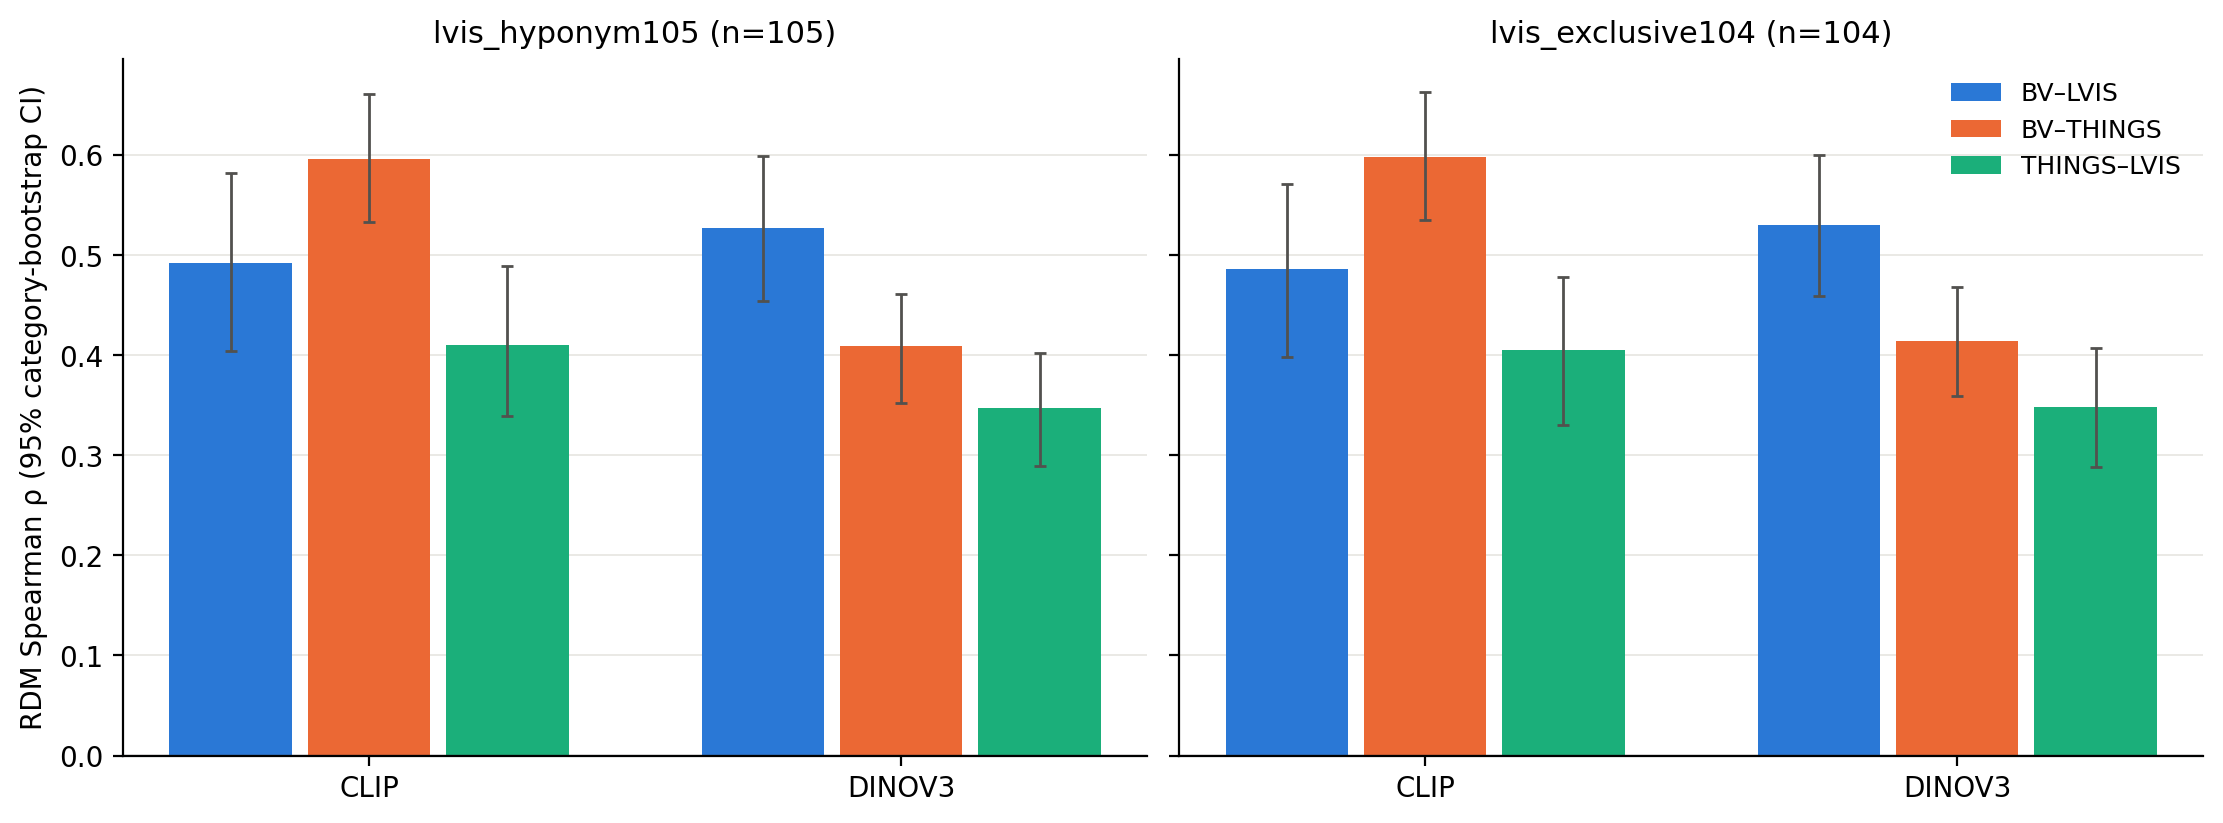

`outputs/bv_lvis/figures/rdms_bv_things_lvis_dinov3_lvis_exclusive104_clustered_bv.png`

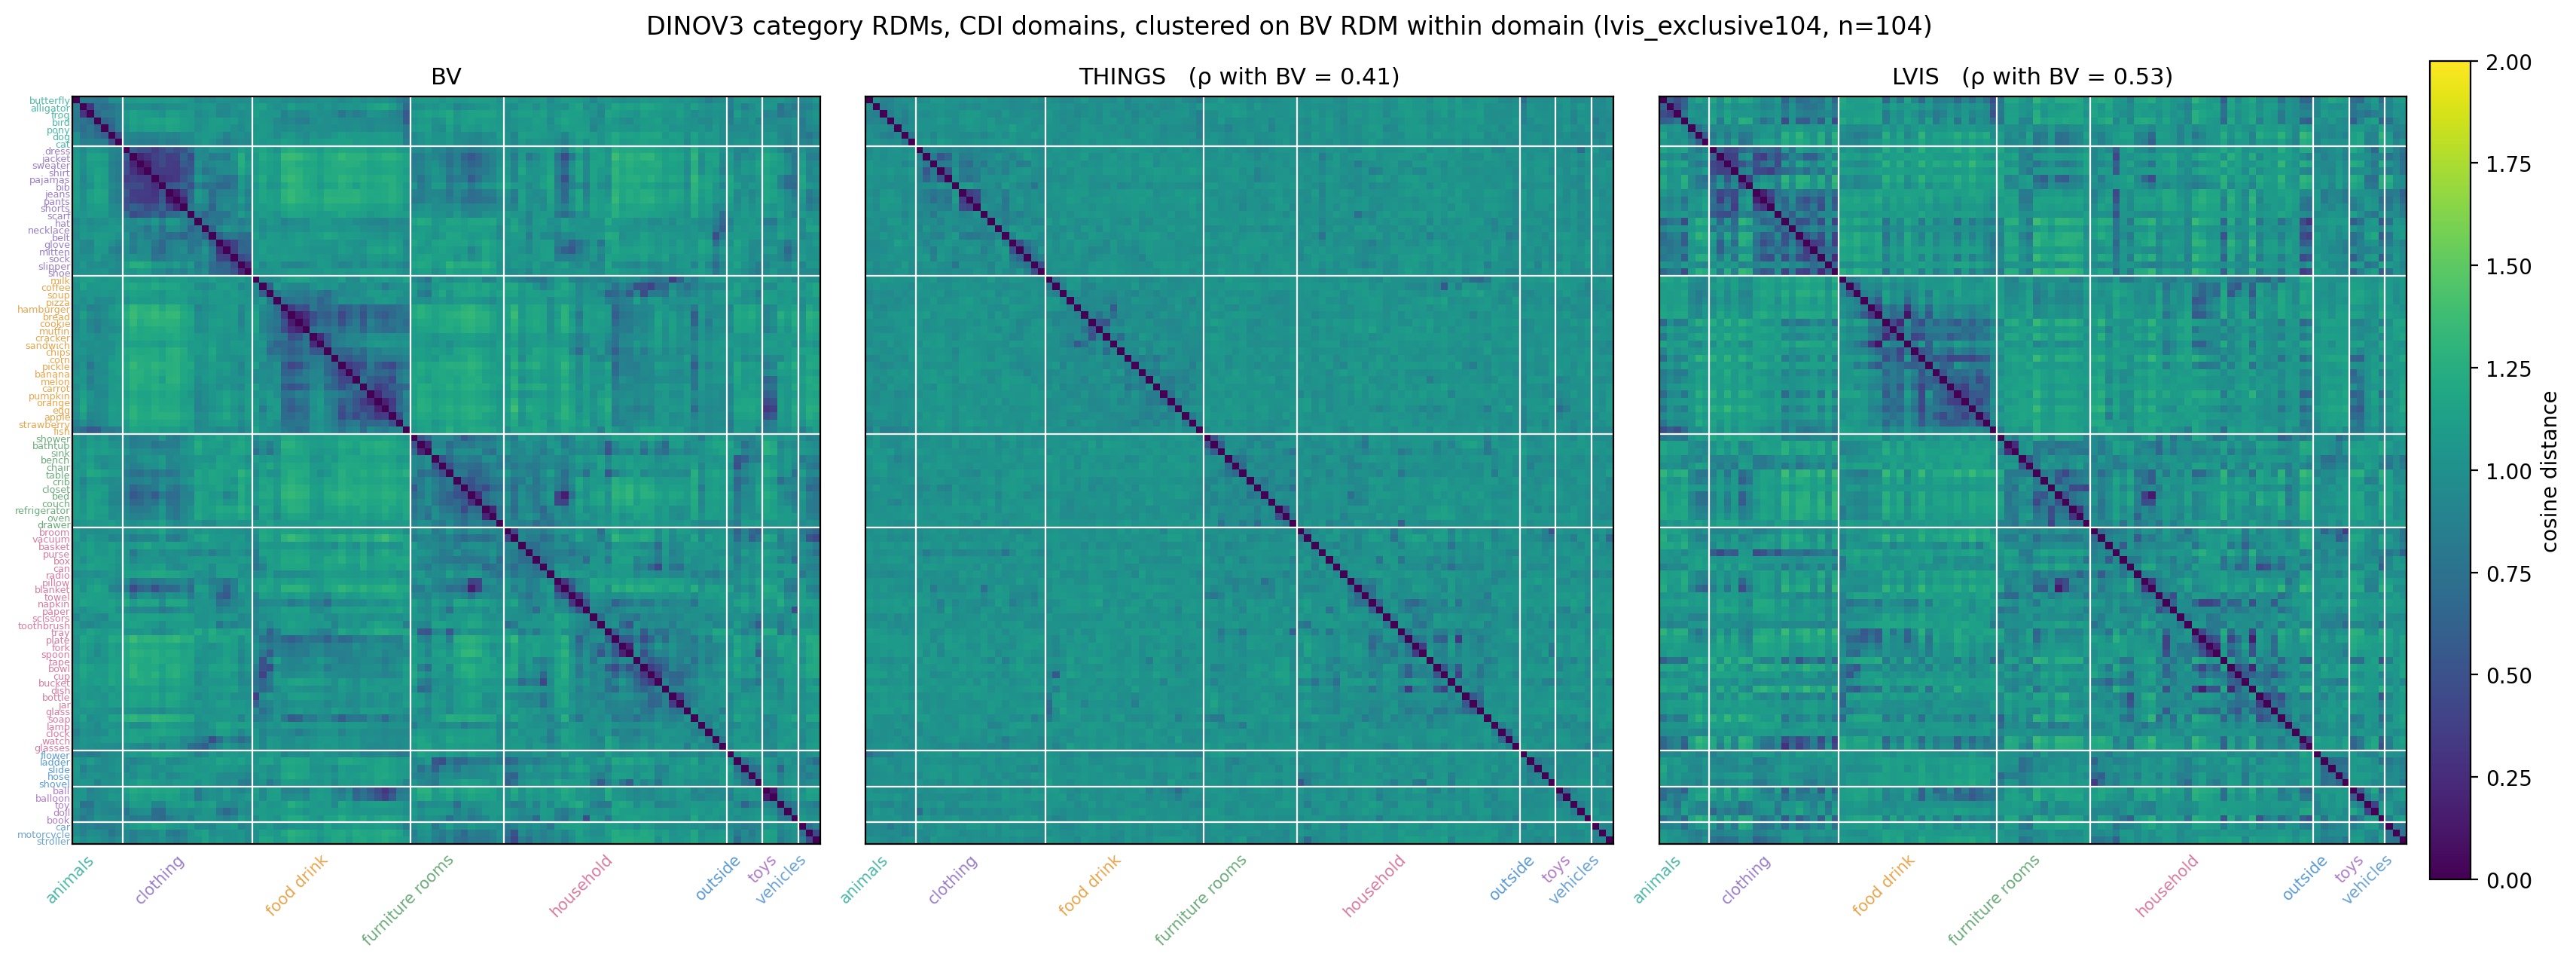

In [11]:
fig = OUT / f"bv_{DATASET}" / "figures"
show_images([fig / f"rdm_spearman_summary_bv_things_{DATASET}.png",
             fig / f"rdms_bv_things_{DATASET}_dinov3_{CATEGORY_SETS[1]}_clustered_bv.png"])

### Review checklist

- Is the permutation one-sided, shuffling only one RDM's labels?
- Does the bootstrap drop pairs of the same original category?
- Do the hyponym and exclusive sets agree (if not, overlapping pools drive the difference)?